In [1]:
import sys
sys.path.append("..")
%load_ext autoreload
%autoreload 2

In [2]:
import os
import pandas as pd
import numpy as np
from dotenv import load_dotenv
from importlib.metadata import version

load_dotenv("../.env")

print("langchain:", version("langchain"))
print("langgraph:", version("langgraph"))
print("gemini key loaded:", bool(os.getenv("GOOGLE_API_KEY")))

langchain: 0.3.27
langgraph: 0.6.2
gemini key loaded: True


In [3]:
from huggingface_hub import hf_hub_download

csv_path = hf_hub_download(
    repo_id="bitext/Bitext-customer-support-llm-chatbot-training-dataset",
    filename="Bitext_Sample_Customer_Support_Training_Dataset_27K_responses-v11.csv",
    repo_type="dataset",
    local_dir="../data/raw"
)
print(csv_path)

/Users/dipanshumandal/Desktop/Capstone/Capstone-2 Agentic RAG/data/raw/Bitext_Sample_Customer_Support_Training_Dataset_27K_responses-v11.csv


In [4]:
df = pd.read_csv(csv_path)
print(df.shape)
df.head()

(26872, 5)


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


In [5]:
df["category"].value_counts()

category
ACCOUNT         5986
ORDER           3988
REFUND          2992
INVOICE         1999
CONTACT         1999
PAYMENT         1998
FEEDBACK        1997
DELIVERY        1994
SHIPPING        1970
SUBSCRIPTION     999
CANCEL           950
Name: count, dtype: int64

In [6]:
print("intents:", df["intent"].nunique())
print(sorted(df["intent"].unique()))

intents: 27
['cancel_order', 'change_order', 'change_shipping_address', 'check_cancellation_fee', 'check_invoice', 'check_payment_methods', 'check_refund_policy', 'complaint', 'contact_customer_service', 'contact_human_agent', 'create_account', 'delete_account', 'delivery_options', 'delivery_period', 'edit_account', 'get_invoice', 'get_refund', 'newsletter_subscription', 'payment_issue', 'place_order', 'recover_password', 'registration_problems', 'review', 'set_up_shipping_address', 'switch_account', 'track_order', 'track_refund']


In [7]:
row = df[df.intent == "track_refund"].iloc[0]
print("Q:", row.instruction)
print("A:", row.response)

Q: can I see if there is anything new on the reimbursement?
A: I understand your eagerness to stay updated on the status of your reimbursement. It's completely natural to want to know if there have been any recent updates. Let me quickly check for any new information regarding your reimbursement. Please bear with me for a moment while I gather the details. Your patience is greatly appreciated as we work towards ensuring your satisfaction and resolving any concerns you may have.


In [8]:
from src.ingestion import load_bitext, split_bitext, bitext_to_documents, load_policy_documents

df = load_bitext()
train_df, holdout_df = split_bitext(df)
print("train:", len(train_df), " holdout:", len(holdout_df))

row = df[df.intent == "track_refund"].iloc[0]
print("A:", row.response[:300])

train: 24184  holdout: 2688
A: I understand your eagerness to stay updated on the status of your reimbursement. It's completely natural to want to know if there have been any recent updates. Let me quickly check for any new information regarding your reimbursement. Please bear with me for a moment while I gather the details. Your


In [9]:
faq_docs = bitext_to_documents(train_df)
policy_docs = load_policy_documents()

print("faq documents:", len(faq_docs))
for d in policy_docs:
    print(d.metadata["source"], "-", len(d.page_content), "chars")

print(policy_docs[0].page_content[:500])

faq documents: 1080
account_and_profile.md - 2446 chars
customer_support.md - 1857 chars
orders_and_cancellation.md - 2116 chars
payments.md - 1910 chars
returns_and_refunds.md - 2112 chars
shipping_and_delivery.md - 2110 chars
# ShopEase Account, Profile and Privacy

Last updated: September 2026

## Creating an account

An account can be created with a mobile number or email address from the Sign Up page. An OTP is sent for verification. One mobile number can be linked to only one account. There is no charge for creating an account.

## Account types

- Standard account: free, available to everyone
- ShopEase Plus: Rs. 499 per year, gives free express delivery on all orders, early access to sales and priority customer


In [10]:
from src.ingestion import chunk_documents

docs = faq_docs + policy_docs
chunks = chunk_documents(docs)

lengths = [len(c.page_content) for c in chunks]
print("documents:", len(docs), " chunks:", len(chunks))
print("chunk length - min:", min(lengths), " mean:", int(np.mean(lengths)), " max:", max(lengths))
print()
print(chunks[0].page_content)
print(chunks[0].metadata)

documents: 1086  chunks: 2789
chunk length - min: 20  mean: 278  max: 500

Customer question: need help to cancel purchase your order number
Support answer: I perceive that you need assistance with canceling purchase your order number. Our main priority is to ensure a smooth and hassle-free cancellation process for you. Here are the steps you can follow:
{'source': 'bitext_faq', 'intent': 'cancel_order', 'category': 'order', 'chunk_id': 'bitext_faq#1'}


In [11]:
[c for c in chunks if c.metadata["source"] == "returns_and_refunds.md"][1]

Document(metadata={'source': 'returns_and_refunds.md', 'intent': 'policy', 'category': 'policy', 'chunk_id': 'returns_and_refunds.md#2'}, page_content='## Return window\n\nMost products can be returned within 10 days of delivery. Electronics and mobile phones have a 7 day return window. Grocery, personal care items, innerwear and customised products cannot be returned unless they arrived damaged or were the wrong item.')

In [12]:
from src.ingestion import get_embeddings, build_faiss
from src.config import INDEX_DIR

embeddings = get_embeddings()
faiss_store = build_faiss(chunks, embeddings)

print("vectors in index:", faiss_store.index.ntotal)
print("dimension:", faiss_store.index.d)
print("saved to:", INDEX_DIR)

/Users/dipanshumandal/Desktop/Capstone/Capstone-2 Agentic RAG/notebooks/../src/ingestion.py:125: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-huggingface package and should be used instead. To use it run `pip install -U :class:`~langchain-huggingface` and import as `from :class:`~langchain_huggingface import HuggingFaceEmbeddings``.
  return HuggingFaceEmbeddings(


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

2026-10-14 12:39:30.827 Python[68195:44873826] Error creating directory 
 The volume ‚ÄúMacintosh HD‚Äù is out of space. You can‚Äôt save the file ‚Äúmpsgraph-68195-2026-10-14_12_39_30-2063631836‚Äù because the volume ‚ÄúMacintosh HD‚Äù is out of space.


vectors in index: 2789
dimension: 384
saved to: /Users/dipanshumandal/Desktop/Capstone/Capstone-2 Agentic RAG/data/index


In [13]:
vec = embeddings.embed_query("where is my parcel")
print(len(vec), vec[:5])

384 [0.04690501093864441, -0.027039997279644012, 0.048489660024642944, -0.040334202349185944, 0.06710755079984665]


In [14]:
from src.ingestion import train_intent_classifier, make_eval_set

clf = train_intent_classifier(train_df, embeddings)
eval_rows = make_eval_set(holdout_df)
print("classes:", len(clf.classes_), " eval questions:", len(eval_rows))

classes: 27  eval questions: 20


In [15]:
from src.retrieval import get_retriever

retriever = get_retriever()
print("chunks loaded:", len(retriever.docs))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

chunks loaded: 2789


In [16]:
def show(results):
    for r in results:
        print(f"{r['score']:.3f}  {r['method']:9s} {r['chunk_id']:28s} {r['intent']:22s} {r['content'][:80]!r}")

q = "how many days do I have to return a phone"
print("semantic:"); show(retriever.semantic_search(q, k=4))
print("\nkeyword:");  show(retriever.keyword_search(q, k=4))
print("\nhybrid:");   show(retriever.hybrid_search(q, k=4))

semantic:
0.774  semantic  returns_and_refunds.md#2     policy                 '## Return window\n\nMost products can be returned within 10 days of delivery. Elec'
0.449  semantic  returns_and_refunds.md#3     policy                 'The item must be unused, in its original packaging and with all tags and accesso'
0.414  semantic  returns_and_refunds.md#6     policy                 '## Damaged, defective or wrong items\n\nIf the product arrived damaged, defective '
0.336  semantic  returns_and_refunds.md#4     policy                 '## Refund methods\n\nRefunds go back to the original payment method by default:\n\n-'

keyword:
14.056  bm25      returns_and_refunds.md#2     policy                 '## Return window\n\nMost products can be returned within 10 days of delivery. Elec'
13.161  bm25      returns_and_refunds.md#3     policy                 'The item must be unused, in its original packaging and with all tags and accesso'
12.287  bm25      bitext_faq#506               check_ref

In [17]:
q = "COD handling fee"
print("semantic:"); show(retriever.semantic_search(q, k=3))
print("\nhybrid:");  show(retriever.hybrid_search(q, k=3))

semantic:
0.350  semantic  bitext_faq#297               check_cancellation_fee 'Customer question: what is the charge for breaking the contract\nSupport answer: '
0.328  semantic  bitext_faq#296               check_cancellation_fee 'Customer question: I want help to check the early termination fees\nSupport answe'
0.326  semantic  bitext_faq#293               check_cancellation_fee "Customer question: I don't know how to see the withdrawal charge\nSupport answer:"

hybrid:
0.507  hybrid    payments.md#2                policy                 '## Accepted payment methods\n\n- UPI (Google Pay, PhonePe, Paytm, BHIM and any UPI'
0.433  hybrid    bitext_faq#287               check_cancellation_fee 'Customer question: i dont know how i can check the cancellation fee\nSupport answ'
0.425  hybrid    bitext_faq#281               check_cancellation_fee "Customer question: how could I see the cancellation fee?\nSupport answer: I'll ta"


In [18]:
sample = holdout_df.sample(200, random_state=1)

def top1_hit(search):
    hits = 0
    for r in sample.itertuples():
        res = search(r.instruction, k=1)
        hits += bool(res) and res[0]["intent"] == r.intent
    return hits / len(sample)

retrieval_check = pd.DataFrame({
    "top-1 intent match": [top1_hit(retriever.semantic_search),
                           top1_hit(retriever.keyword_search),
                           top1_hit(retriever.hybrid_search)]
}, index=["semantic", "bm25", "hybrid"])
retrieval_check

,top-1 intent match
semantic,0.930
bm25,0.905
hybrid,0.945


In [19]:
from src.agents import RESPONSE_PROMPT
print(RESPONSE_PROMPT)

You are the customer support assistant of {company}, an Indian e-commerce store.
Answer the customer's question using ONLY the context below. The context has FAQ answers and policy text.
If the context does not contain the answer, say that you do not have that information and suggest contacting support.
Do not invent order details, fees or dates. Keep the answer short (3 to 6 sentences), plain text, no markdown.
{tone}

CONTEXT:
{context}

CHAT HISTORY (older messages first):
{history}

CUSTOMER QUESTION: {question}

Reply with JSON only, in this exact shape:
{{"answer": "<your answer>", "sources_used": [<numbers of the context items you used>], "confidence": <0 to 1>}}



In [20]:
from src.llm import call_llm, parse_json
from src.config import COMPANY

q = "can I pay with an international card"
chunks_for_q = retriever.hybrid_search(q, k=3)
context = "\n".join(f"[{i+1}] ({c['source']}) {c['content']}" for i, c in enumerate(chunks_for_q))

prompt = RESPONSE_PROMPT.format(company=COMPANY, tone="Be friendly and to the point.", context=context,
                                history="(no previous messages)", question=q)
raw, model_used = call_llm(prompt)
print("model:", model_used)
print(raw)
print()
print(parse_json(raw))

model: gemini-3.8-flash
{"answer": "We accept all major credit and debit cards, including Visa, Mastercard, and American Express, as well as PayPal, which is used worldwide. However, I do not have specific information regarding whether international cards are supported. Please contact our customer support team for further assistance. They will be happy to help clarify your payment options.", "sources_used": [1, 3], "confidence": 0.7}

{'answer': 'We accept all major credit and debit cards, including Visa, Mastercard, and American Express, as well as PayPal, which is used worldwide. However, I do not have specific information regarding whether international cards are supported. Please contact our customer support team for further assistance. They will be happy to help clarify your payment options.', 'sources_used': [1, 3], 'confidence': 0.7}


In [21]:
from src.tools import ALL_TOOLS, rag_search, classify_intent, analyse_sentiment, rewrite_query, check_escalation

for t in ALL_TOOLS:
    print(f"{t.name:18s} {t.description}")

rag_search         Search the ShopEase knowledge base (FAQ answers and policy documents) and return the top k chunks.
classify_intent    Query Understanding agent. Predicts the customer's intent (27 bitext intents) and its category with a confidence.
analyse_sentiment  Sentiment agent. Returns the sentiment label (negative / neutral / positive), VADER score and urgency.
rewrite_query      Rewrites a query whose context failed validation: drops order / invoice numbers, adds the intent keywords.
check_escalation   Escalation agent. Decides whether the conversation goes to a human support executive, creates a ticket if so.


In [23]:
classify_intent.invoke({"text": "I want to delete my account"})

{'intent': 'delete_account', 'category': 'account', 'confidence': 0.981}

In [24]:
analyse_sentiment.invoke({"text": "third time asking, my refund is STILL not here. unacceptable!!"})

{'sentiment': 'neutral', 'score': -0.271, 'urgency': 'high'}

In [25]:
rewrite_query.invoke({"query": "where is my order SE12345678 ?", "intent": "track_order"})

'where is my order track order'

In [26]:
check_escalation.invoke({"intent": "complaint", "sentiment": "negative", "urgency": "high",
                         "validation_passed": True, "confidence": 0.8})

{'escalate': True,
 'reasons': ["customer intent is 'complaint'",
  'negative sentiment with high urgency'],
 'priority': 'high',
 'ticket_id': 'CS-6F7174'}

In [27]:
sample = holdout_df.sample(500, random_state=2)
pred = [classify_intent.invoke({"text": t})["intent"] for t in sample.instruction]
print("intent accuracy on 500 held out questions:", round((np.array(pred) == sample.intent.values).mean(), 3))

intent accuracy on 500 held out questions: 0.996


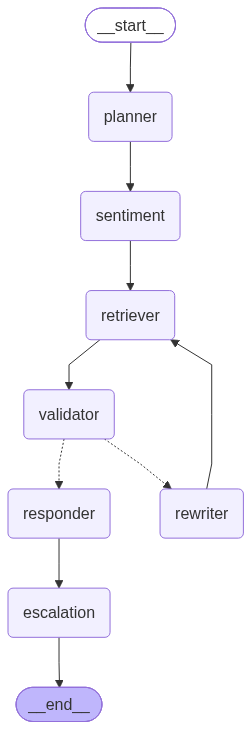

In [28]:
from src.graph import build_graph, run_query
from IPython.display import Image, display

app = build_graph()
try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    print(app.get_graph().draw_ascii())

In [29]:
def ask(q, session="demo"):
    r = run_query(q, session_id=session, app=app)
    print("Q:", q)
    print("A:", r["answer"])
    print()
    print("intent:", r["intent"], f"({r['intent_confidence']})", "| category:", r["category"])
    print("sentiment:", r["sentiment"])
    print("plan:", r["plan"])
    print("agents invoked:", " -> ".join(r["agents_invoked"]))
    print("validation:", r["validation"], "| retries:", r["retries"])
    print("sources:", r["sources"], "| confidence:", r["confidence"], "| llm:", r["llm_model"])
    print("escalation:", r["escalation"])
    return r

r = ask("How do I track my order?")

Q: How do I track my order?
A: You can track your order by visiting our website at www.shopease.com and logging into your account. Once logged in, navigate to the Order History, Track Order, or My Orders section to check the latest updates on your order. Additionally, every dispatched order is sent a tracking number via SMS and email, which you can enter directly on our courier partner's website. Please note that tracking updates can take up to 12 hours to appear after your package has been dispatched.

intent: track_order (0.905) | category: order
sentiment: {'sentiment': 'neutral', 'score': 0.0, 'urgency': 'low'}
plan: ['classify_intent', 'analyse_sentiment', 'rag_search', 'validate_context', 'generate_answer', 'check_escalation']
agents invoked: planner -> sentiment -> retriever -> validator -> responder -> escalation
validation: {'passed': True, 'relevance': 0.846, 'intent_agreement': 1.0, 'score': 0.908, 'reason': 'context is relevant and matches the intent'} | retries: 0
sources:

In [30]:
r = ask("and what if it is late?")          

Q: and what if it is late?
A: I do not have specific information regarding policies for late deliveries. You can check the latest estimated arrival time by visiting the 'My Orders > Track' section on our website. If your order is delayed, please reach out directly to our customer support team at 1800-123-4567. They will be able to look into your delivery and provide you with the most up-to-date information.

intent: track_order (0.593) | category: order
sentiment: {'sentiment': 'neutral', 'score': 0.0, 'urgency': 'low'}
plan: ['classify_intent', 'analyse_sentiment', 'rag_search', 'validate_context', 'generate_answer', 'check_escalation']
agents invoked: planner -> sentiment -> retriever -> validator -> responder -> escalation
validation: {'passed': True, 'relevance': 0.801, 'intent_agreement': 0.67, 'score': 0.747, 'reason': 'context is relevant and matches the intent'} | retries: 0
sources: ['bitext_faq#2604'] | confidence: 0.77 | llm: gemini-3.8-flash
escalation: {'escalate': False, 

In [31]:
state = app.get_state({"configurable": {"thread_id": "demo"}}).values
for m in state["messages"]:
    print(type(m).__name__, ":", m.content[:100])

HumanMessage : How do I track my order?
AIMessage : You can track your order by visiting our website at www.shopease.com and logging into your account. 
HumanMessage : and what if it is late?
AIMessage : I do not have specific information regarding policies for late deliveries. You can check the latest 


In [32]:
r = ask("I have been asking for 2 weeks, nobody is refunding my money, this is a scam, I want to talk to a human right now!!", session="angry")

Q: I have been asking for 2 weeks, nobody is refunding my money, this is a scam, I want to talk to a human right now!!
A: I am truly sorry for the delay and frustration you have experienced regarding your refund. I understand how important it is to get your money back and resolve this issue promptly. I recommend reaching out to our customer support team directly through our website or by phone so a team member can assist you with your request. To help process this smoothly, please have your purchase details, the reason for the refund, and any relevant documentation ready.

I have also raised ticket CS-10E782 with our support team (high priority). A support executive will get back to you within 24 hours.

intent: get_refund (0.535) | category: refund
sentiment: {'sentiment': 'negative', 'score': -0.691, 'urgency': 'high'}
plan: ['classify_intent', 'analyse_sentiment', 'rag_search', 'validate_context', 'generate_answer', 'check_escalation']
agents invoked: planner -> sentiment -> retriev

In [33]:
r = ask("what is the cancellation fee if my order was already dispatched", session="policy")

Q: what is the cancellation fee if my order was already dispatched
A: If your order has already been dispatched, you can still cancel it, but applicable fees will be deducted. For orders below Rs. 1000, the cancellation fee is Rs. 50. For orders of Rs. 1000 or more, the fee is 5% of the order value, capped at a maximum of Rs. 500. Please note that any delivery charges paid will not be refunded.

intent: check_cancellation_fee (0.69) | category: cancel
sentiment: {'sentiment': 'neutral', 'score': 0.0, 'urgency': 'low'}
plan: ['classify_intent', 'analyse_sentiment', 'rag_search', 'validate_context', 'generate_answer', 'check_escalation']
agents invoked: planner -> sentiment -> retriever -> validator -> responder -> escalation
validation: {'passed': True, 'relevance': 0.83, 'intent_agreement': 1.0, 'score': 0.898, 'reason': 'context is relevant and matches the intent'} | retries: 0
sources: ['orders_and_cancellation.md#4'] | confidence: 0.95 | llm: gemini-3.8-flash
escalation: {'escalate'

In [34]:
r = ask("do you sell tickets for the cricket world cup", session="nokb")   # validator fails -> retries -> escalation

Q: do you sell tickets for the cricket world cup
A: Thank you for reaching out to ShopEase. I apologize, but I do not have the information regarding whether we sell tickets for the Cricket World Cup. I recommend contacting our customer support team directly so they can check this for you. Our team is always here and happy to assist with your queries.

I have also raised ticket CS-0EABB4 with our support team (normal priority). A support executive will get back to you within 24 hours.

intent: delivery_options (0.479) | category: delivery
sentiment: {'sentiment': 'neutral', 'score': 0.0, 'urgency': 'low'}
plan: ['classify_intent', 'analyse_sentiment', 'rag_search', 'validate_context', 'generate_answer', 'check_escalation']
agents invoked: planner -> sentiment -> retriever -> validator -> rewriter -> retriever -> validator -> rewriter -> retriever -> validator -> responder -> escalation
validation: {'passed': False, 'relevance': 0.254, 'intent_agreement': 0.12, 'score': 0.202, 'reason': 

In [35]:
from src.feedback import save_feedback, feedback_summary

save_feedback("demo", "How do I track my order?", r["answer"], "up", intent="track_order")
save_feedback("demo", "is there a fee for express delivery to Goa",
              "Express delivery is Rs. 99.", "down",
              correction="Express delivery costs Rs. 99 but Goa pin codes are not serviceable for express, only standard delivery.",
              intent="delivery_options")
feedback_summary()

{'total': 2,
 'up': 1,
 'down': 1,
 'corrections': 1,
 'thumbs_down_by_intent': {'delivery_options': 1}}

In [36]:
retriever.reload_corrections()
show(retriever.hybrid_search("express delivery charge for Goa", k=3))

0.932  correction human_correction             delivery_options       'Verified answer (from support team): Express delivery costs Rs. 99 but Goa pin c'
0.773  hybrid    shipping_and_delivery.md#2   policy                 '## Delivery options\n\nShopEase offers three delivery options at checkout:\n\n| Opti'
0.738  hybrid    bitext_faq#1262              delivery_options       '2. Expedited Shipping: If you need faster delivery, our expedited shipping optio'
0.605  hybrid    shipping_and_delivery.md#7   policy                 '## International shipping\n\nShopEase currently delivers only within India. Intern'


In [37]:
r = ask("how much is express delivery to Goa", session="fb")

Q: how much is express delivery to Goa
A: Express delivery normally costs Rs. 99 at ShopEase. However, Goa pin codes are not serviceable for express delivery, so this option is unavailable for your address. Only standard delivery is available for Goa, which takes 4 to 7 business days. Standard delivery is free on orders above Rs. 499, or Rs. 49 otherwise.

intent: delivery_options (0.49) | category: delivery
sentiment: {'sentiment': 'neutral', 'score': 0.0, 'urgency': 'low'}
plan: ['classify_intent', 'analyse_sentiment', 'rag_search', 'validate_context', 'generate_answer', 'check_escalation']
agents invoked: planner -> sentiment -> retriever -> validator -> responder -> escalation
validation: {'passed': True, 'relevance': 0.912, 'intent_agreement': 1.0, 'score': 0.947, 'reason': 'context is relevant and matches the intent'} | retries: 0
sources: ['human_correction', 'shipping_and_delivery.md#2'] | confidence: 0.95 | llm: gemini-3.8-flash
escalation: {'escalate': False, 'reasons': [], '

In [38]:
from src.evaluation import compare, load_eval_set

eval_set = load_eval_set()
pd.DataFrame(eval_set)[["intent", "question"]]

,intent,question
0,contact_human_agent,i dont know what i need to do to speak with a ...
1,track_order,where could i check order your order number fu...
2,payment_issue,I try to notify of an error with online payments
3,create_account,i have a problem with opening a ShopEase Plus ...
4,check_payment_methods,how could I see the payment methods?
5,recover_password,help to restore the PIN code of my profile
6,registration_problems,where do I inform of an issue with a signup?
7,edit_account,assistance correcting the damn data on my user...
8,get_invoice,I want help to get my bill from the customer
9,switch_account,switch to ShopEase Plus account


In [39]:
results, summary = compare(save=True)
summary.T

[baseline] 1/20 bleu=0.010 rougeL=0.245 rel=0.864 (gemini-3.8-flash)
[baseline] 2/20 bleu=0.001 rougeL=0.104 rel=0.654 (gemini-3.8-flash)
[baseline] 3/20 bleu=0.013 rougeL=0.204 rel=0.862 (gemini-3.8-flash)
[baseline] 4/20 bleu=0.006 rougeL=0.164 rel=0.846 (gemini-3.8-flash)
[baseline] 5/20 bleu=0.000 rougeL=0.107 rel=0.744 (gemini-3.8-flash)
[llm] gemini-3.8-flash quota hit, trying fallback
[baseline] 6/20 bleu=0.005 rougeL=0.219 rel=0.859 (gemini-3.5-flash-lite)
[llm] gemini-3.8-flash quota hit, trying fallback
[baseline] 7/20 bleu=0.002 rougeL=0.202 rel=0.822 (gemini-3.5-flash-lite)
[llm] gemini-3.8-flash quota hit, trying fallback
[baseline] 8/20 bleu=0.001 rougeL=0.151 rel=0.531 (gemini-3.5-flash-lite)
[llm] gemini-3.8-flash quota hit, trying fallback
[baseline] 9/20 bleu=0.005 rougeL=0.145 rel=0.671 (gemini-3.5-flash-lite)
[llm] gemini-3.8-flash quota hit, trying fallback
[baseline] 10/20 bleu=0.000 rougeL=0.135 rel=0.682 (gemini-3.5-flash-lite)
[llm] gemini-3.8-flash quota hit, 

pipeline,agentic,baseline
bleu,0.0454,0.0338
rouge1,0.3614,0.2742
rouge2,0.1309,0.1151
rougeL,0.2315,0.1967
relevance,0.7667,0.7411
context_precision,0.9875,0.9500
intent_accuracy,1.0000,NaN


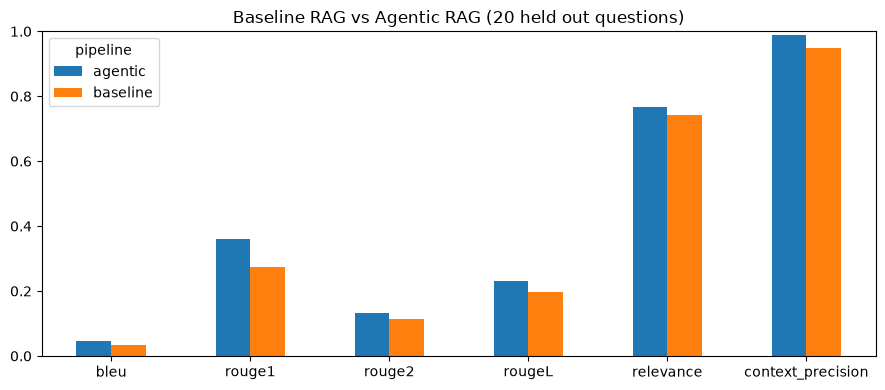

In [40]:
import matplotlib.pyplot as plt
from src.config import EVAL_DIR

ax = summary[["bleu", "rouge1", "rouge2", "rougeL", "relevance", "context_precision"]].T.plot(kind="bar", figsize=(9, 4), rot=0)
ax.set_title("Baseline RAG vs Agentic RAG (20 held out questions)")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(str(EVAL_DIR / "baseline_vs_agentic.png"), dpi=120)
plt.show()

In [41]:
results[["pipeline", "intent", "bleu", "rougeL", "relevance", "context_precision", "llm_model"]]

,pipeline,intent,bleu,rougeL,relevance,context_precision,llm_model
0,baseline,contact_human_agent,0.0102,0.2452,0.8635,1.0000,gemini-3.8-flash
1,baseline,track_order,0.0012,0.1042,0.6543,1.0000,gemini-3.8-flash
2,baseline,payment_issue,0.0125,0.2044,0.8618,1.0000,gemini-3.8-flash
3,baseline,create_account,0.0058,0.1639,0.8464,1.0000,gemini-3.8-flash
4,baseline,check_payment_methods,0.0000,0.1067,0.7435,1.0000,gemini-3.8-flash
5,baseline,recover_password,0.0049,0.2188,0.8594,1.0000,gemini-3.5-flash-lite
6,baseline,registration_problems,0.0018,0.2016,0.8224,1.0000,gemini-3.5-flash-lite
7,baseline,edit_account,0.0014,0.1515,0.5312,1.0000,gemini-3.5-flash-lite
8,baseline,get_invoice,0.0054,0.1449,0.6708,0.6667,gemini-3.5-flash-lite
9,baseline,switch_account,0.0002,0.1350,0.6818,1.0000,gemini-3.5-flash-lite


In [42]:
piv = results.pivot(index="intent", columns="pipeline", values="rougeL")
piv["gain"] = piv["agentic"] - piv["baseline"]
piv.sort_values("gain", ascending=False)

pipeline,agentic,baseline,gain
intent,,,
switch_account,0.4020,0.1350,0.2670
get_refund,0.2969,0.1319,0.1650
track_order,0.2677,0.1042,0.1635
check_payment_methods,0.2366,0.1067,0.1299
get_invoice,0.2286,0.1449,0.0837
edit_account,0.2208,0.1515,0.0693
contact_human_agent,0.3105,0.2452,0.0653
set_up_shipping_address,0.2007,0.1532,0.0475
payment_issue,0.2484,0.2044,0.0440


In [43]:
i = 0
print("QUESTION :", eval_set[i]["question"])
print("REFERENCE:", eval_set[i]["reference"][:400])
print()
print("BASELINE :", results[results.pipeline == "baseline"].iloc[i].answer[:400])
print()
print("AGENTIC  :", results[results.pipeline == "agentic"].iloc[i].answer[:400])

QUESTION : i dont know what i need to do to speak with a live agent
REFERENCE: We're listening! I'm keyed into the fact that you're unsure about how to speak with a live agent. Don't worry, I'm here to help! To connect with a live agent, you can try a few different options. You can navigate to our website and look for a "Contact Us" or "Support" page, where you may find options for live chat, email, or phone support. Alternatively, you can try calling our customer service ho

BASELINE : To speak with a live agent, you can click on the Chat with Us button on our website or call our customer support hotline at 1800-123-4567.

AGENTIC  : Thank you for reaching out, I am here to help you connect with a live agent! To speak with a human agent, you can look for a Contact Us or Support section on our website or app. There you will find options to reach us through phone, email, or live chat support. Please bear with a moment while we connect you to one of our dedicated human representatives.

